# Potato Disease Classification

Dataset credits: https://www.kaggle.com/arjuntejaswi/plant-village

### Import all the Dependencies

In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
from IPython.display import HTML

In [59]:
# from google.cloud import storage
# from PIL import Image

In [56]:
# print(tf.__version__)

2.6.0


In [58]:
# print(storage.__version__)

2.19.0


In [60]:
# print(Image.__version__)

8.2.0


### Import data into tensorflow dataset object

Used splitfolders tool to split dataset into training, validation and test directories.

$ pip install split-folders

$ splitfolders --ratio 0.8 0.1 0.1 -- ./training/PlantVillage/


In [4]:
# !pip install split-folders
# 80%->train, 10%->validation, 10%->test in this order, output-> receiving folder after split op, PlantVillage-> folder of the whole img
# !splitfolders --output output --ratio 0.8 0.1 0.1 -- PlantVillage


Copying files: 0 files [00:00, ? files/s]
Copying files: 1 files [00:00,  3.29 files/s]
Copying files: 4 files [00:00, 11.33 files/s]
Copying files: 6 files [00:00, 13.94 files/s]
Copying files: 10 files [00:00, 20.36 files/s]
Copying files: 14 files [00:00, 22.97 files/s]
Copying files: 17 files [00:00, 24.33 files/s]
Copying files: 21 files [00:00, 28.42 files/s]
Copying files: 25 files [00:01, 28.38 files/s]
Copying files: 29 files [00:01, 30.39 files/s]
Copying files: 34 files [00:01, 34.28 files/s]
Copying files: 38 files [00:01, 33.90 files/s]
Copying files: 42 files [00:01, 32.92 files/s]
Copying files: 47 files [00:01, 36.76 files/s]
Copying files: 52 files [00:01, 39.13 files/s]
Copying files: 57 files [00:01, 41.92 files/s]
Copying files: 62 files [00:02, 41.36 files/s]
Copying files: 67 files [00:02, 41.39 files/s]
Copying files: 72 files [00:02, 41.76 files/s]
Copying files: 77 files [00:02, 40.99 files/s]
Copying files: 82 files [00:02, 37.25 files/s]
Copying files: 86 fi

Copying files: 1258 files [00:31, 45.07 files/s]
Copying files: 1264 files [00:31, 47.04 files/s]
Copying files: 1269 files [00:31, 45.25 files/s]
Copying files: 1274 files [00:31, 38.86 files/s]
Copying files: 1279 files [00:31, 39.56 files/s]
Copying files: 1284 files [00:31, 41.74 files/s]
Copying files: 1290 files [00:32, 42.90 files/s]
Copying files: 1295 files [00:32, 43.62 files/s]
Copying files: 1300 files [00:32, 43.09 files/s]
Copying files: 1306 files [00:32, 45.28 files/s]
Copying files: 1312 files [00:32, 47.19 files/s]
Copying files: 1318 files [00:32, 45.16 files/s]
Copying files: 1323 files [00:32, 42.12 files/s]
Copying files: 1328 files [00:32, 43.50 files/s]
Copying files: 1334 files [00:33, 45.94 files/s]
Copying files: 1340 files [00:33, 47.64 files/s]
Copying files: 1345 files [00:33, 45.31 files/s]
Copying files: 1351 files [00:33, 45.31 files/s]
Copying files: 1356 files [00:33, 45.12 files/s]
Copying files: 1361 files [00:33, 44.84 files/s]
Copying files: 1366 

In [5]:
IMAGE_SIZE = 256
CHANNELS = 3

In [24]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ImageDataGenerator is working as basic python generator function
train_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=10,
        horizontal_flip=True
)
train_generator = train_datagen.flow_from_directory(
        'output/train',
        # target_size=(-1, IMAGE_SIZE,IMAGE_SIZE, 1),
        target_size=(IMAGE_SIZE,IMAGE_SIZE),
        batch_size=32,
        class_mode="sparse",
        # save_to_dir="C:\\Code\\potato-disease-classification\\training\\AugmentedImages"
)

Found 1721 images belonging to 3 classes.


In [25]:
train_generator.class_indices

{'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}

In [26]:
class_names = list(train_generator.class_indices.keys())
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [27]:
count=0
for image_batch, label_batch in train_generator:
    # print(label_batch)
    print(image_batch[0])
    break
#     count+=1
#     if count>2:
#         break

[[[0.6901961  0.6666667  0.6745098 ]
  [0.6924501  0.6689207  0.67676383]
  [0.69411767 0.67058825 0.6784314 ]
  ...
  [0.57945156 0.5559221  0.5637652 ]
  [0.57711136 0.55358195 0.5614251 ]
  [0.5747712  0.5512418  0.55908495]]

 [[0.6901961  0.6666667  0.6745098 ]
  [0.6918651  0.6683357  0.6761788 ]
  [0.69411767 0.67058825 0.6784314 ]
  ...
  [0.5674558  0.5439264  0.55176955]
  [0.56687075 0.54334134 0.5511845 ]
  [0.5662857  0.5427563  0.55059946]]

 [[0.6901961  0.6666667  0.6745098 ]
  [0.69128    0.6677506  0.67559373]
  [0.69411767 0.67058825 0.6784314 ]
  ...
  [0.56808925 0.54455984 0.552403  ]
  [0.56984437 0.54631495 0.5541581 ]
  [0.5715995  0.5480701  0.5559132 ]]

 ...

 [[0.6541005  0.63057107 0.6384142 ]
  [0.65234536 0.62881595 0.6366591 ]
  [0.64980984 0.6262804  0.63412356]
  ...
  [0.5760476  0.5172241  0.5289888 ]
  [0.5372708  0.47844723 0.49021193]
  [0.49461785 0.4357943  0.447559  ]]

 [[0.6254414  0.6019119  0.6097551 ]
  [0.62017596 0.59664655 0.6044897 ]


In [28]:
validation_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=10,
        horizontal_flip=True)
validation_generator = validation_datagen.flow_from_directory(
        'output/val',
        target_size=(IMAGE_SIZE,IMAGE_SIZE),
        batch_size=32,
        class_mode="sparse"
)

Found 215 images belonging to 3 classes.


In [29]:
test_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=10,
        horizontal_flip=True)

test_generator = test_datagen.flow_from_directory(
        'output/test',
        target_size=(IMAGE_SIZE,IMAGE_SIZE),
        batch_size=32,
        class_mode="sparse"
)

Found 216 images belonging to 3 classes.


In [14]:
for image_batch, label_batch in test_generator:
    print(image_batch[0])
    break

[[[0.5650895  0.4945013  0.5415601 ]
  [0.5535486  0.48296034 0.53001916]
  [0.5420076  0.47141936 0.51847816]
  ...
  [0.689429   0.6149192  0.6384486 ]
  [0.73718655 0.65954405 0.6924715 ]
  [0.6868002  0.6083688  0.6436629 ]]

 [[0.5827305  0.51214224 0.55920106]
  [0.61652905 0.5459408  0.59299964]
  [0.6503277  0.5797394  0.6267982 ]
  ...
  [0.68984115 0.61533135 0.63886076]
  [0.7433692  0.66531456 0.69947857]
  [0.6785566  0.6001252  0.6354193 ]]

 [[0.33832833 0.2677401  0.31479892]
  [0.3337944  0.26320612 0.31026497]
  [0.33054015 0.25995192 0.30701074]
  ...
  [0.69105417 0.61648715 0.64018816]
  [0.74831    0.66987866 0.7051728 ]
  [0.67049193 0.59206057 0.6273547 ]]

 ...

 [[0.5521983  0.4541591  0.4698454 ]
  [0.5334938  0.43545455 0.45114082]
  [0.53249526 0.43445602 0.4501423 ]
  ...
  [0.5441847  0.4479086  0.465358  ]
  [0.5281098  0.43100932 0.44763437]
  [0.51203483 0.41411003 0.42991072]]

 [[0.5505496  0.4525104  0.46819666]
  [0.5314329  0.43339366 0.44907993]


## Building the Model

In [30]:
input_shape = (IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    layers.InputLayer(input_shape=input_shape),
    layers.Conv2D(32, kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

In [31]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_6 (Conv2D)            (None, 254, 254, 32)      896       
_________________________________________________________________
max_pooling2d_6 (MaxPooling2 (None, 127, 127, 32)      0         
_________________________________________________________________
conv2d_7 (Conv2D)            (None, 125, 125, 64)      18496     
_________________________________________________________________
max_pooling2d_7 (MaxPooling2 (None, 62, 62, 64)        0         
_________________________________________________________________
conv2d_8 (Conv2D)            (None, 60, 60, 64)        36928     
_________________________________________________________________
max_pooling2d_8 (MaxPooling2 (None, 30, 30, 64)        0         
_________________________________________________________________
conv2d_9 (Conv2D)            (None, 28, 28, 64)       

### Compiling the Model
We use `adam` Optimizer, `SparseCategoricalCrossentropy` for losses, `accuracy` as a metric

In [32]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [33]:
1721/32

53.78125

In [34]:
215/32

6.71875

In [35]:
history = model.fit(
    train_generator,
    steps_per_epoch=53,
    batch_size=32,
    validation_data=validation_generator,
    validation_steps=6,
    verbose=1,
    epochs=20,
)

Epoch 1/20
53/53 [==============================] - 225s 4s/step - loss: 0.8932 - accuracy: 0.5287 - val_loss: 0.7759 - val_accuracy: 0.6875
Epoch 2/20
53/53 [==============================] - 165s 3s/step - loss: 0.5837 - accuracy: 0.7271 - val_loss: 0.4123 - val_accuracy: 0.8281
Epoch 3/20
53/53 [==============================] - 176s 3s/step - loss: 0.3541 - accuracy: 0.8550 - val_loss: 0.2743 - val_accuracy: 0.8958
Epoch 4/20
53/53 [==============================] - 171s 3s/step - loss: 0.2595 - accuracy: 0.8917 - val_loss: 0.2379 - val_accuracy: 0.9062
Epoch 5/20
53/53 [==============================] - 170s 3s/step - loss: 0.1975 - accuracy: 0.9218 - val_loss: 0.2079 - val_accuracy: 0.9219
Epoch 6/20
53/53 [==============================] - 167s 3s/step - loss: 0.1779 - accuracy: 0.9290 - val_loss: 0.2027 - val_accuracy: 0.9323
Epoch 7/20
53/53 [==============================] - 175s 3s/step - loss: 0.1650 - accuracy: 0.9331 - val_loss: 0.2551 - val_accuracy: 0.9115
Epoch 8/20
53

In [36]:
scores = model.evaluate(test_generator)

7/7 [==============================] - 15s 2s/step - loss: 0.0760 - accuracy: 0.9722


In [37]:
scores

[0.07604140788316727, 0.9722222089767456]

Scores is just a list containing loss and accuracy value

### Plotting the Accuracy and Loss Curves

In [3]:
history

history
history.params
history


You can read documentation on history object here: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/History

In [4]:
history.params

NameError: name 'history' is not defined

In [40]:
history.history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

**loss, accuracy, val loss etc are a python list containing values of loss, accuracy etc at the end of each epoch**

In [41]:
type(history.history['loss'])

list

In [42]:
len(history.history['loss'])

20

In [43]:
history.history['loss'][:5] # show loss for first 5 epochs

[0.8931650519371033,
 0.5837159156799316,
 0.35405904054641724,
 0.2594696879386902,
 0.19754569232463837]

In [44]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

In [45]:
val_acc

[0.6875,
 0.828125,
 0.8958333134651184,
 0.90625,
 0.921875,
 0.9322916865348816,
 0.9114583134651184,
 0.90625,
 0.9166666865348816,
 0.96875,
 0.9479166865348816,
 0.9583333134651184,
 0.890625,
 0.9583333134651184,
 0.9010416865348816,
 0.9791666865348816,
 0.9895833134651184,
 0.9791666865348816,
 0.9739583134651184,
 0.9427083134651184]

In [46]:
acc

[0.528715193271637,
 0.7270574569702148,
 0.8549528121948242,
 0.8916518688201904,
 0.9218472242355347,
 0.9289520382881165,
 0.9330965280532837,
 0.9561870694160461,
 0.9585553407669067,
 0.9616745114326477,
 0.9709887504577637,
 0.9733570218086243,
 0.9881587028503418,
 0.9656601548194885,
 0.9632918834686279,
 0.9739490747451782,
 0.9893428087234497,
 0.9905269145965576,
 0.9881587028503418,
 0.9680284261703491]

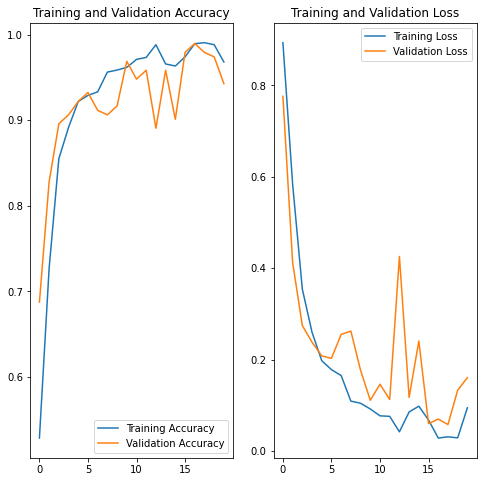

In [47]:
EPOCHS = 20

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label='Training Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

### Run prediction on a sample image

first image to predict
actual label: Potato___Early_blight
predicted label: Potato___Early_blight


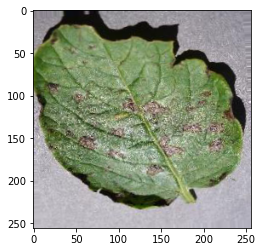

In [48]:
import numpy as np


for image_batch, label_batch in test_generator:
    first_image = image_batch[0]
    first_label = int(label_batch[0])
    
    print("first image to predict")
    plt.imshow(first_image)
    print("actual label:",class_names[first_label])
    # print(image_batch)
    
    batch_prediction = model.predict(image_batch)
    print("predicted label:",class_names[np.argmax(batch_prediction[0])])
    
    break

### Write a function for inference

In [51]:
def predict_(model, img):
    # Ensure image has 3 channels (convert grayscale to RGB)
    if img.shape[-1] == 1:  # Check if the image is grayscale
        img = tf.image.grayscale_to_rgb(img)  # Convert to RGB
        
    img_array = tf.keras.preprocessing.image.img_to_array(img) # img[i]
    # print(img_array)
    img_array = tf.expand_dims(img_array, 0)
    # print("#"*25)
    
    # print(img_array)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

**Now run inference on few sample images**

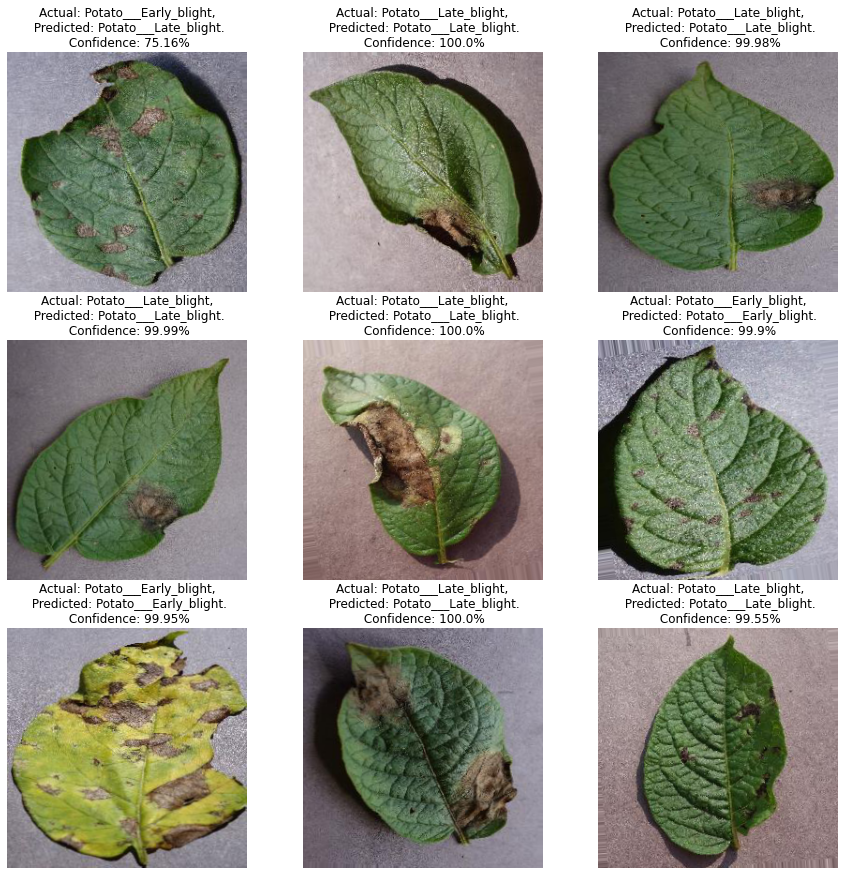

In [52]:
plt.figure(figsize=(15, 15))
for images, labels in test_generator:
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        
        # Ensure images are displayed in RGB format
        img = images[i]
        if img.shape[-1] == 1:  # Convert grayscale to RGB for display
            img = tf.image.grayscale_to_rgb(img)
        plt.imshow(img)
        
        predicted_class, confidence = predict_(model, images[i])
        actual_class = class_names[int(labels[i])] 
        
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        
        plt.axis("off")
    break

### Saving the Model

Save model in h5 format so that there is just one file and we can upload that to GCP conveniently

In [53]:
import os
# below one getting next model version
# go to paste dir n return it content as list + add 0 to list then converted elt into int, then pick the maximum one elt of the list.
model_version = max(int(i) for i in os.listdir("../saved_models") + [0]) + 1 # used to save our model in #t version
model.save(f"../saved_models/{model_version}.h5")
# model.save("../potatoes.h5")